In [33]:
from astropy.io import fits

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import stats as ss
from scipy.io import readsav
from sklearn.decomposition import PCA

from tqdm import tqdm

import tools as t

## Load data

In [34]:
# load files
path_data = '../data/sim_series/'  # directory where the files are saved
N_files = 20  # 20 temporal series (from 0 to 19)
data_spectra = []
data_rv = []
for i in range(N_files):  # files have the same name, only number changes
    data_spectra.append(fits.getdata(path_data + f'flux_norm_6173_lionel_tau1_spatialscaling1_sansrotation_serie{i}.fits'))
    data_rv.append(readsav(path_data + f'res_rv_bis_6173_lionel_tau1_scaling1_sansrot_serie{i}.sav'))
data_spectra = np.array(data_spectra)
data_rv = np.array(data_rv)
print(data_rv[0].keys())

dict_keys(['rv_gauss', 'rv_correl', 'rv_deriv', 'xbiss', 'ybiss', 'l_true', 'lambd', 'flux_moy'])


In [35]:
c = 3e8  # speed of light [m/s]
# extract data
wl = np.array(data_rv[0]['lambd'])  # same wavelength grid for all time series (verified)
times = np.arange(0, len(data_spectra[0]) * 144, 144) / 60 / 24  # time in days, same for all time series
times_sec = times * 86400  # time in sec
# extract RV data
wl = np.array(wl)

## Work with only one TS

In [140]:
# selecting TS
ts_index = 5

spectra_ex = data_spectra[ts_index]

# splitting TS in two halves
N = len(times)
N_half = N // 2

times_half = times[:N_half]

spectra_0 = spectra_ex[:N_half]
spectra_1 = spectra_ex[N_half:]

## Preprocessing

In [141]:
# calculate the mean spectra
mean_spec_0 = np.mean(spectra_0, axis=0)
mean_spec_1 = np.mean(spectra_1, axis=0)

d_S0 = np.gradient(mean_spec_0, wl)
d_S1 = np.gradient(mean_spec_1, wl)

In [142]:
Sf_0, D_0 = t.subtract_D(wl, spectra_0, c=c)  # S_f and Doppler vector
Sf_1, D_1 = t.subtract_D(wl, spectra_1, c=c)

spectra_centered_0 = t.double_centering(Sf_0)
spectra_centered_1 = t.double_centering(Sf_1)

In [143]:
# preprocessing all TS
mean_spec = np.array([np.mean(i, axis=0) for i in data_spectra])  # list of mean spectrum for each TS
d_S0 = np.array([np.gradient(i, wl) for i in mean_spec])  # list of derivative of the mean spectra for each TS

S_f = []  # array of matrices
D_vectors = []  # array of Doppler vectors

for i in range(N_files):  # for each TS
    s, v = t.subtract_D(wl, data_spectra[i], c=c)  # take out projection over the Doppler vector
    S_f.append(s)
    D_vectors.append(v)

S_f = np.array(S_f)
D_vectors = np.array(D_vectors)

spectra_centered = np.array([t.double_centering(i) for i in S_f])

## Calculate RV by template matching

In [144]:
# calculate radial velocity by template matching
C_0 = 1000  # continuum constant

# list of RVs for each timestep
rv_0 = np.array([
    t.calculate_rv(wl, mean_spec_0, spectra_0[i], C_0) for i in range(N_half)
    ])

rv_1 = np.array([
    t.calculate_rv(wl, mean_spec_1, spectra_1[i], C_0) for i in range(N_half)
    ])

In [145]:
# calculate RV for all the TS

rv_tm = []  # list of RV vector for each TS
for j in range(N_files):  # for each TS
    rv_j = []
    for k in range(len(times)):  # for each spectrum
        rv_j.append(t.calculate_rv(wl, mean_spec[j], data_spectra[j][k], C_0))  # calculate RV by TM
    rv_tm.append(np.array(rv_j))
rv_tm = np.array(rv_tm)

## PCA

In [146]:
# apply PCA to the centered matrix
n_components = 16

# first half
pca_flux_0 = PCA(n_components=n_components)           # create PCA object
pcs_0 = pca_flux_0.fit_transform(spectra_centered_0)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_0 = pca_flux_0.components_                   # save loadings
scores_0 = pcs_0.T                                    # save scores
var_0 = pca_flux_0.explained_variance_ratio_          # save PC variation

# second half
pca_flux_1 = PCA(n_components=n_components)           # create PCA object
pcs_1 = pca_flux_1.fit_transform(spectra_centered_1)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_1 = pca_flux_1.components_                   # save loadings
scores_1 = pcs_1.T                                    # save scores
var_1 = pca_flux_1.explained_variance_ratio_          # save PC variation

In [147]:
print(f'Centred TS of spectra shape: {spectra_centered_0.shape}')
print(f'Loadings shape: {loadings_0.shape}')
print(f'Scores shape: {scores_0.shape}')

Centred TS of spectra shape: (1843, 122)
Loadings shape: (16, 122)
Scores shape: (16, 1843)


In [148]:
# checking if the projection of spectra_centered over the loadings is equal to the scores

proj_0 = []
for i in range(n_components):
    proj_i = []
    loadings_i = loadings_0[i]
    for j in range(N_half):
        proj_ij = np.dot(loadings_i.T, spectra_centered_0[j]) / np.linalg.norm(loadings_i)**2
        proj_i.append(proj_ij)
    proj_0.append(proj_i)
proj_0 = np.array(proj_0)

In [149]:
(np.round(scores_0, 15) == np.round(proj_0, 15)).all()

np.True_

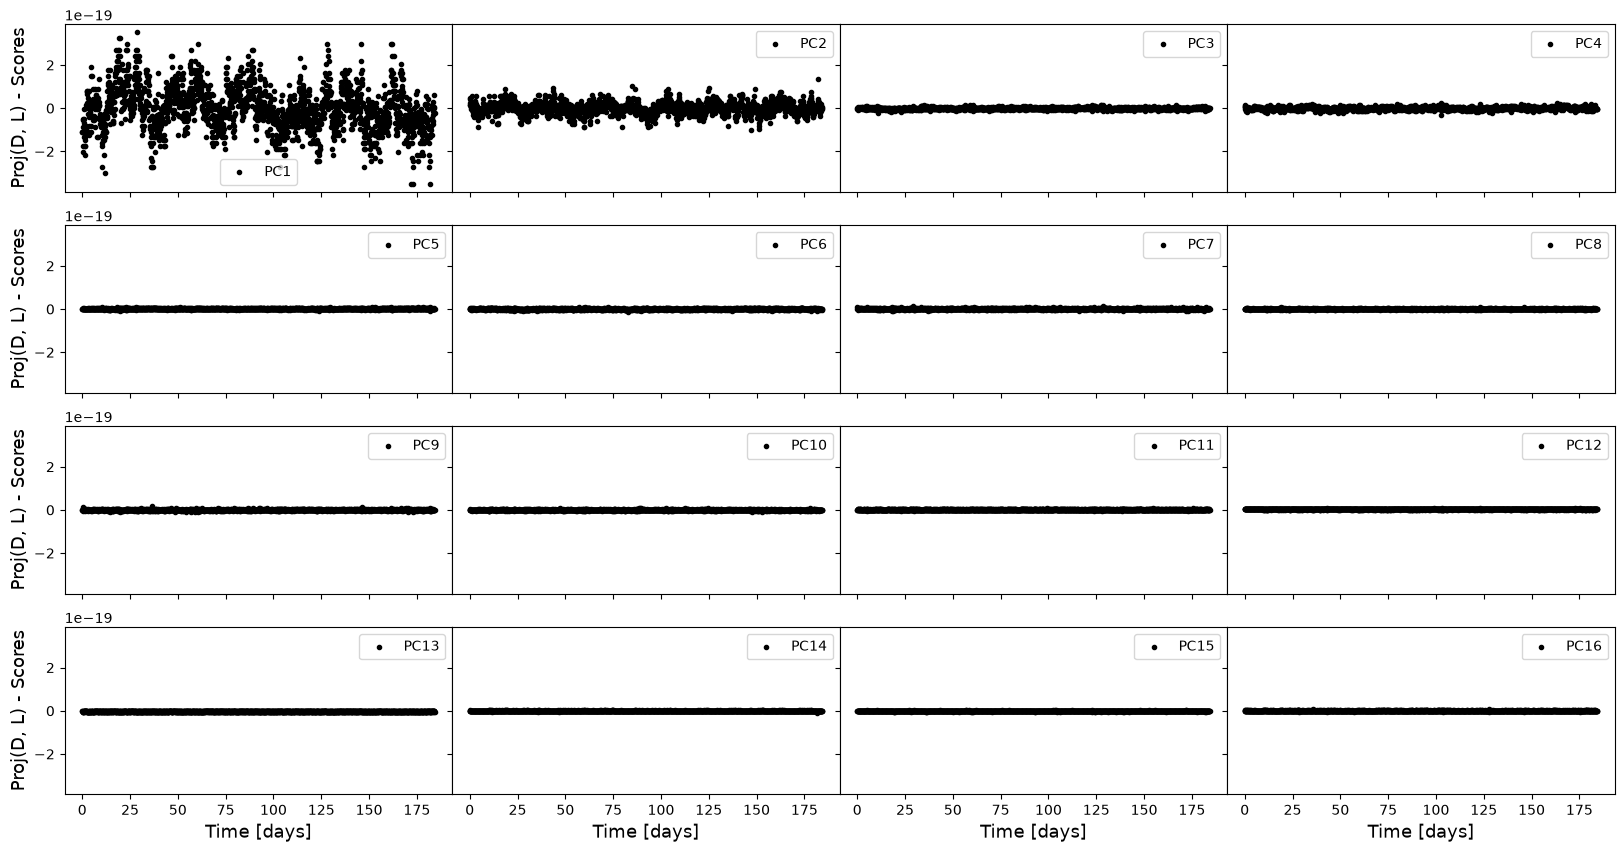

In [150]:
# plot difference between scores and projections for each PC
rows = 4
cols = 4
fig, axs = plt.subplots(rows, cols, figsize=(20, 10), sharex=True, sharey=True)

pc = 0  # PC counter
for row in range(rows):
    for col in range(cols):
        axs[row][col].scatter(times_half, proj_0[pc] - scores_0[pc], color='k', marker='.', label=f'PC{pc + 1}')
        if row == rows - 1:
            axs[row][col].set_xlabel('Time [days]', size=13)
        if col == 0:
            axs[row][col].set_ylabel('Proj(D, L) - Scores', size=13)
        axs[row][col].legend()
        pc += 1

plt.subplots_adjust(wspace=0)
plt.show()

In [151]:
# smallest score values vs maximum difference
for i in range(len(scores_0)):
    print(f'PC {i+1}: Minimum score: {min(np.abs(scores_0[i])):.2e}; Maximum difference: {max(proj_0[i] - scores_0[i]):.2e}.')

PC 1: Minimum score: 5.93e-08; Maximum difference: 3.52e-19.
PC 2: Minimum score: 1.35e-08; Maximum difference: 1.36e-19.
PC 3: Minimum score: 1.09e-09; Maximum difference: 1.69e-20.
PC 4: Minimum score: 3.14e-09; Maximum difference: 2.29e-20.
PC 5: Minimum score: 1.95e-09; Maximum difference: 1.02e-20.
PC 6: Minimum score: 1.14e-10; Maximum difference: 1.04e-20.
PC 7: Minimum score: 1.90e-10; Maximum difference: 1.27e-20.
PC 8: Minimum score: 4.25e-11; Maximum difference: 1.13e-20.
PC 9: Minimum score: 9.63e-12; Maximum difference: 1.72e-20.
PC 10: Minimum score: 2.29e-11; Maximum difference: 8.83e-21.
PC 11: Minimum score: 3.43e-12; Maximum difference: 7.68e-21.
PC 12: Minimum score: 2.92e-11; Maximum difference: 8.29e-21.
PC 13: Minimum score: 3.39e-11; Maximum difference: 1.02e-21.
PC 14: Minimum score: 2.61e-11; Maximum difference: 4.37e-21.
PC 15: Minimum score: 8.51e-12; Maximum difference: 5.18e-21.
PC 16: Minimum score: 3.77e-12; Maximum difference: 8.20e-21.


## Linear Model

In [152]:
# train/test split
train_size = int(.7 * N_half)
# I_train_0  = scores_0.T[:train_size]  # matrix with scores as columns
I_train_0 = proj_0.T[:train_size]  # using pseudo-scores
rv_true_train_0 = rv_0[:train_size]
times_train = times_half[:train_size]

#I_test_0  = scores_0.T[train_size:]  # matrix with scores as columns
I_test_0 = proj_0.T[train_size:]  # using pseudo-scores
spectra_centered_test_0 = spectra_centered_0[train_size:]
rv_true_test_0 = rv_0[train_size:]
times_test = times_half[train_size:]

# training the model
G = np.dot(I_train_0.T, I_train_0)
b = np.dot(I_train_0.T, rv_true_train_0)
alpha = np.linalg.solve(G, b)

In [153]:
proj_0.shape, scores_0.shape

((16, 1843), (16, 1843))

In [154]:
alpha

array([ 4.80350051e+03,  1.63949429e+04,  9.28445893e+04, -6.84881536e+04,
       -1.35083333e+05, -5.24394796e+05,  5.29430335e+05,  3.62960564e+05,
        2.25215452e+05,  1.07842053e+05,  1.02578705e+06,  6.57726289e+06,
        2.59337557e+06,  2.29123577e+06,  4.67052519e+06,  9.64159210e+06])

In [155]:
# checking dot(G, alpha) = b
np.allclose(np.dot(G, alpha), b)

True

Scores using the whole TS (from linear_testing.ipynb):

```
array([ 6.3795771e+03,  1.6776572e+04,  7.8773547e+04, -7.0820305e+04,
       -7.8339969e+04, -4.8443328e+05,  4.6573222e+05,  6.1937944e+05,
        3.9534394e+05,  4.9364572e+05,  4.6065034e+05,  6.0899435e+06,
        1.5968818e+06,  1.8360150e+06, -1.0490876e+07,  7.1286250e+06,
        2.8292119e+05, -3.1375859e+05,  1.2220842e+06, -9.8916838e+05],
      dtype=float32)
```

In [156]:
# testing on the test sample of the same half

chunk_size = 21   # using chunks to get error bars

rv_pred_test_0 = []    # list of chunks of predicted RV
res_test_0 = []        # list of chunks of residuals calculated from rv_pred
res_sigma_test_0 = []  # list of numbers: std of each chunk in res

j = 0
while j < len(rv_true_test_0):  # iterate over chunks
    if j + chunk_size > len(rv_true_test_0):  # last elements of the TS not included if (N % chunk_size != 0)
        break

    else:
        pseudo_scores_j = I_test_0[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
        rv_true_j = rv_true_test_0[j:j+chunk_size]  # chunk_size values of RV
        
        rv_pred_j = np.dot(pseudo_scores_j, alpha)  # predict chunk_size values of RV
        res_j = rv_true_j - rv_pred_j  # chunk residuals

        rv_pred_test_0.append(rv_pred_j)        # append chunk of resulting RV to a list
        res_test_0.append(res_j)                # append residuals of each chunk
        res_sigma_test_0.append(np.std(res_j))  # append std of res_j
    j += chunk_size

rv_pred_test_0 = np.array(rv_pred_test_0)
res_test_0 = np.array(res_test_0)
res_test_0_flat = res_test_0.flatten()
res_sigma_test_0 = np.array(res_sigma_test_0)

# without chunks
#rv_pred_test_0 = np.dot(I_test_0, alpha)
#res_test_0 = rv_true_test_0 - rv_pred_test_0
#std_res_0 = np.std(res_test_0)

In [157]:
pseudo_scores_j.shape, alpha.shape

((21, 16), (16,))

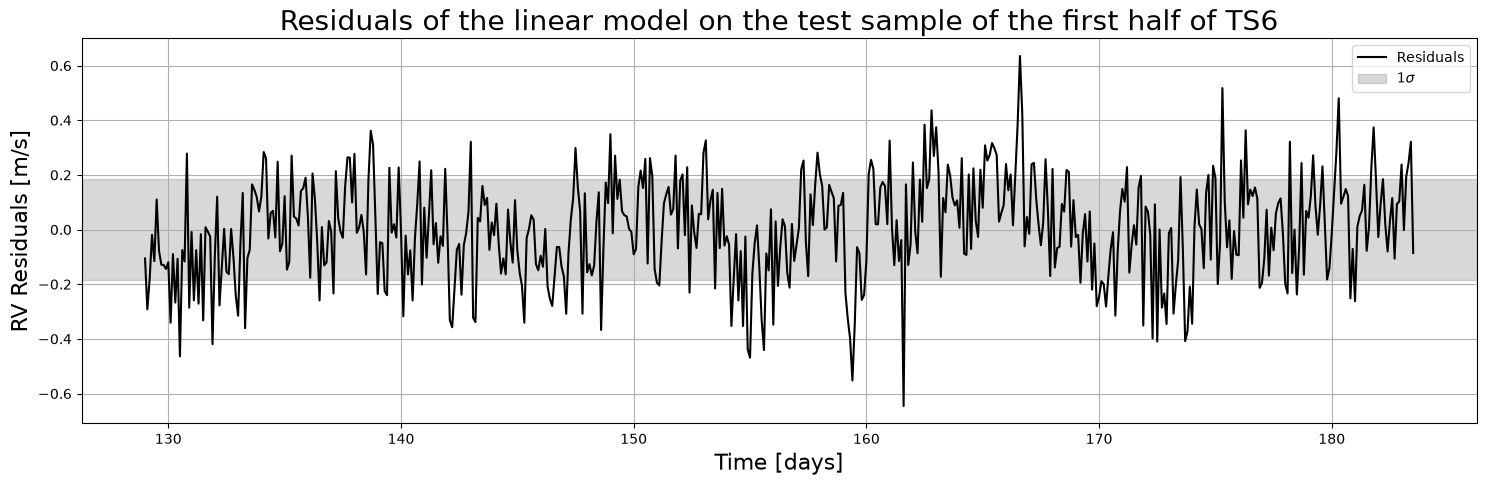

In [158]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.set_title(f'Residuals of the linear model on the test sample of the first half of TS{ts_index + 1}', size=20)

ax.grid()
ax.plot(times_test[:len(res_test_0_flat)], res_test_0_flat, color='k', label='Residuals')
ax.axhspan(-np.std(res_test_0), np.std(res_test_0), color='gray', alpha=.3, label=r'$1\sigma$')

ax.set_xlabel('Time [days]', size=16)
ax.set_ylabel('RV Residuals [m/s]', size=16)
ax.legend()

plt.show()

In [159]:
print(f'The standard deviation of the residuals is {np.std(res_test_0):.3f} m/s.')  # using pseudo-scores gives the ssame result as using scores

The standard deviation of the residuals is 0.185 m/s.


In [160]:
# calculating pseudo-scores for the second half
proj_1 = []
for i in range(n_components):
    proj_i = []
    loadings_i = loadings_0[i]  # using loadings from the first half
    for j in range(N_half):
        proj_ij = np.dot(loadings_i.T, spectra_centered_1[j]) / np.linalg.norm(loadings_i)**2  # projecting spectra from the second half on the loadings from the first half
        proj_i.append(proj_ij)
    proj_1.append(proj_i)
proj_1 = np.array(proj_1)

# testing on the whole second half

rv_pred_1 = []    # list of chunks of predicted RV
res_1 = []        # list of chunks of residuals calculated from rv_pred
res_sigma_1 = []  # list of numbers: std of each chunk in res

j = 0
while j < N_half:  # iterate over chunks
    if j + chunk_size > N_half:  # last elements of the TS not included if (N % chunk_size != 0)
        break

    else:
        pseudo_scores_j = proj_1.T[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
        rv_true_j = rv_1[j:j+chunk_size]  # chunk_size values of RV

        rv_pred_j = np.dot(pseudo_scores_j, alpha)  # predict chunk_size values of RV
        res_j = rv_true_j - rv_pred_j  # chunk residuals

        rv_pred_1.append(rv_pred_j)        # append chunk of resulting RV to a list
        res_1.append(res_j)                # append residuals of each chunk
        res_sigma_1.append(np.std(res_j))  # append std of res_j
    j += chunk_size

rv_pred_1 = np.array(rv_pred_1)
res_1 = np.array(res_1)
res_1_flat = res_1.flatten()
res_sigma_1 = np.array(res_sigma_1)

#I_1 = scores_1.T  # using scores
#I_1 = proj_1.T  # using pseudo-scores

#rv_pred_1 = np.dot(I_1, alpha)
#res_1 = rv_1 - rv_pred_1
#std_res_1 = np.std(res_1)

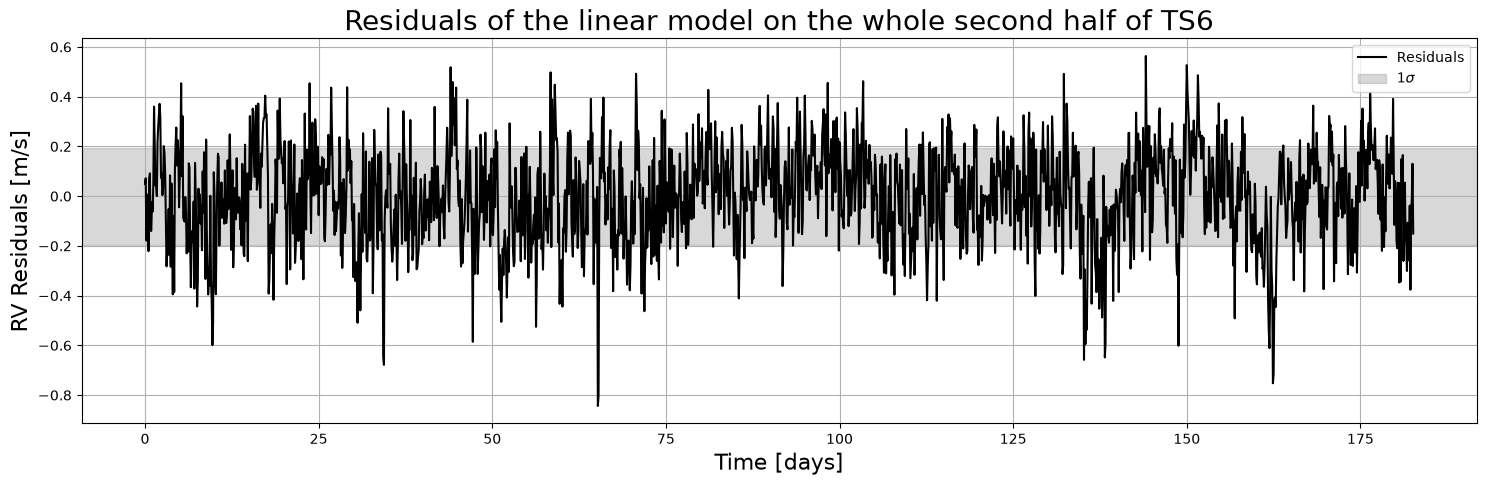

In [161]:
fig, ax = plt.subplots(figsize=(18, 5))
ax.set_title(f'Residuals of the linear model on the whole second half of TS{ts_index + 1}', size=20)

ax.grid()
ax.plot(times_half[:len(res_1_flat)], res_1_flat, color='k', label='Residuals')
ax.axhspan(-np.std(res_1), np.std(res_1), color='gray', alpha=.3, label=r'$1\sigma$')

ax.set_xlabel('Time [days]', size=16)
ax.set_ylabel('RV Residuals [m/s]', size=16)
ax.legend()

plt.show()

In [162]:
print(f'The standard deviation of the residuals is {np.std(res_1):.3f} m/s.')  # much better than using scores!

The standard deviation of the residuals is 0.195 m/s.


In [163]:
print(len(res_1.flatten()))
print(len(rv_1[:len(res_1.flatten())]))

1827
1827


## Testing on all other TS

In [164]:
# create pseudo-scores fo each TS, using spectra_centered and loadings_0
pseudo_scores = []

for k in range(N_files):  # iterate over TS
    spectra_centered_k = spectra_centered[k]
    proj_k = []
    for i in range(n_components):  # iterate over PCs
        proj_i = []
        loadings_i = loadings_0[i]  # using reference loadings
        for j in range(N):  # iterate over timesteps
            proj_ij = np.dot(loadings_i.T, spectra_centered_k[j]) / np.linalg.norm(loadings_i)**2  # projecting spectra on the reference loadings
            proj_i.append(proj_ij)
        proj_k.append(proj_i)
    pseudo_scores.append(proj_k)

pseudo_scores = np.array(pseudo_scores)

In [165]:
# check shape
print(pseudo_scores.shape)

(20, 16, 3686)


In [166]:
# testing with chunks
#max_len = (N // chunk_size) * chunk_size

rv_pred = []
res = []
res_sigma = []

for i in range(N_files):  # iterate over TS

    pseudo_scores_i = pseudo_scores[i]
    rv_true_i = rv_tm[i]

    rv_pred_i = []    # list of chunks of predicted RV
    res_i = []        # list of chunks of residuals calculated from rv_pred_i
    res_sigma_i = []  # list of numbers: std of each chunk in res_i

    j = 0

    while j < N:  # iterate over chunks

        if j + chunk_size > N:  # last elements of the TS not included if (N % chunk_size != 0)
            break

        else:
            pseudo_scores_j = pseudo_scores_i.T[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
            rv_true_j = rv_true_i[j:j+chunk_size]  # chunk_size values of RV

            rv_pred_j = np.dot(pseudo_scores_j, alpha)  # predict chunk_size values of RV
            res_j = rv_true_j - rv_pred_j  # chunk residuals
            
            rv_pred_i.append(rv_pred_j)        # append chunk of resulting RV to a list
            res_i.append(res_j)                # append residuals of each chunk
            res_sigma_i.append(np.std(res_j))  # append std of res_j
        
        j += chunk_size

    rv_pred.append(np.array(rv_pred_i))
    res.append(np.array(res_i))
    res_sigma.append(np.array(res_sigma_i))

rv_pred = np.array(rv_pred)
res = np.array(res)
res_sigma = np.array(res_sigma)

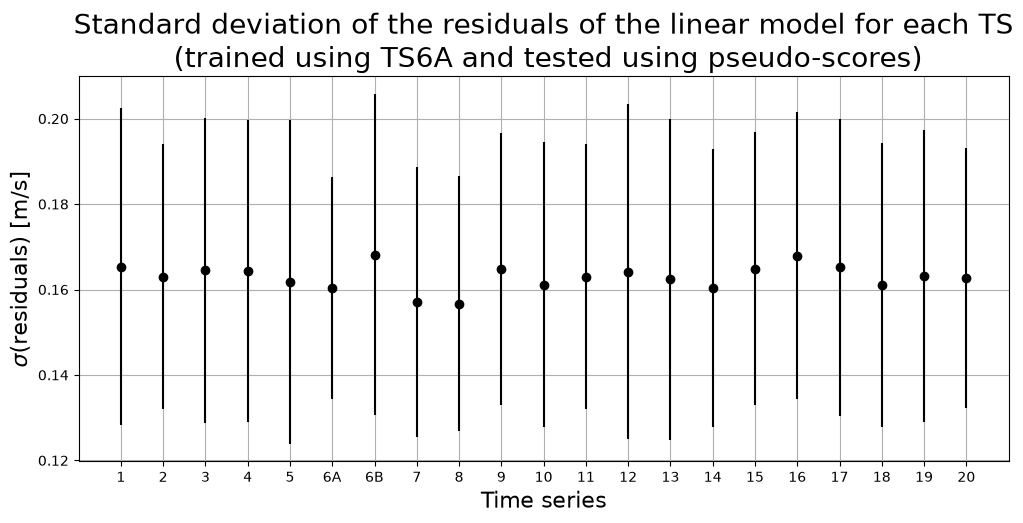

In [167]:
# show std for each TS
ts_arr = np.linspace(1, N_files + 1, N_files + 1)  # array of integers from 1 to the number of TS (+1 to account for splitting the first TS)

# show results for TS1A and TS1B separated instead of example TS as a whole
y = np.mean(res_sigma, axis=1)
y_err = np.std(res_sigma, axis=1)

y = np.delete(y, ts_index)  # taking out example TS
y_err = np.delete(y_err, ts_index)

y = np.insert(y, ts_index, np.mean(res_sigma_1))  # inserting TS1B results
y_err = np.insert(y_err, ts_index, np.std(res_sigma_1))

y = np.insert(y, ts_index, np.mean(res_sigma_test_0))  # inserting TS1A results
y_err = np.insert(y_err, ts_index, np.std(res_sigma_test_0))

# create a list for xticklabels
xticklabels = []
for i in range(1, N_files + 1):
    if i == ts_index + 1:
        xticklabels.append(f"{i}A")
        xticklabels.append(f"{i}B")
    else:
        xticklabels.append(str(i))

# plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title(f'Standard deviation of the residuals of the linear model for each TS\n (trained using TS{ts_index+1}A and tested using pseudo-scores)', size=20)

ax.grid()
ax.errorbar(ts_arr, y, y_err, fmt='o', color='k', zorder=2)

ax.set_xlabel('Time series', size=16)
ax.set_ylabel(r'$\sigma$(residuals) [m/s]', size=16)

ax.set_xticks(ts_arr)
ax.set_xticklabels(xticklabels)

plt.show()

In [168]:
# mean and standard deviation of the residuals (per chunk) for TS1B
print(f'Sigma(res) = {np.mean(res_sigma_1):.3f} +- {np.std(res_sigma_1):.3f}')

Sigma(res) = 0.168 +- 0.038


In [169]:
print(len(rv_true_test_0[:len(res_test_0.flatten())]))
print(len(res_test_0.flatten()))

546
546


In [170]:
res_sigma_test_0

array([0.15241617, 0.1376156 , 0.1537286 , 0.14375225, 0.17781781,
       0.15239208, 0.18305342, 0.11369963, 0.15390213, 0.15956002,
       0.1530823 , 0.14303073, 0.16482362, 0.13852232, 0.22627451,
       0.20813845, 0.15144643, 0.15625385, 0.13073764, 0.12594445,
       0.19897742, 0.19676644, 0.17825903, 0.15906572, 0.17209432,
       0.13623753])

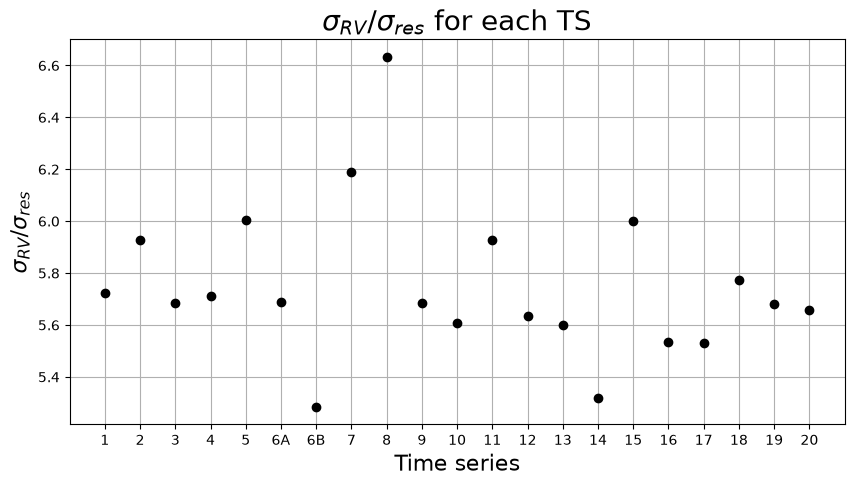

In [171]:
# sigma(RV) / sigma(residuals)
sigma_rv = np.std(rv_tm, axis=1)  # standard deviation of the RVs of each TS
sigma_ratio = sigma_rv / np.mean(res_sigma, axis=1)

y = np.delete(sigma_ratio, ts_index)

# insert TS1B and TS1A
y = np.insert(y, ts_index, np.std(rv_1[:len(res_1.flatten())]) / np.mean(res_sigma_1))  # the RV arrays are cut to account for the points left out when chunking
y = np.insert(y, ts_index, np.std(rv_true_test_0[:len(res_test_0.flatten())]) / np.mean(res_sigma_test_0))

fig, ax = plt.subplots(figsize=(10, 5))

ax.set_title(r'$\sigma_{RV} / \sigma_{res}$ for each TS', size=20)

ax.grid()
ax.scatter(ts_arr, y, color='k', zorder=2)

ax.set_xlabel('Time series', size=16)
ax.set_ylabel(r'$\sigma_{RV} / \sigma_{res}$', size=16)
ax.set_xticks(ts_arr)
ax.set_xticklabels(xticklabels)

plt.show()